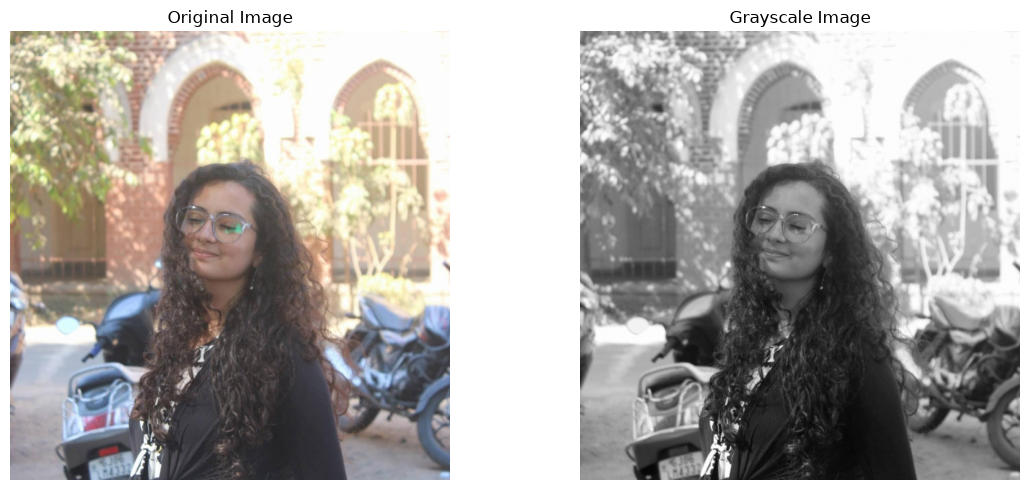

Image loaded successfully: (1304, 1279, 3)


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

image_path = Path("../data/images/original.jpeg")
image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(f"Image not found: {image_path.resolve()}")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Image loaded successfully:", image.shape)


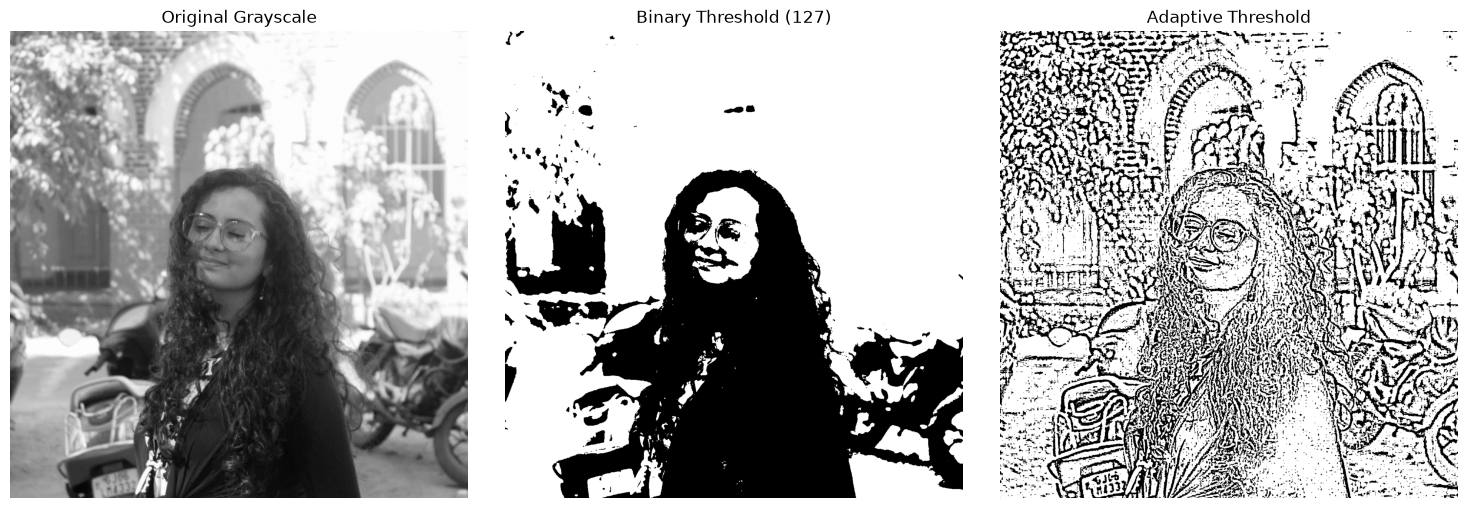

In [3]:
# Experiment 1: Binary and Adaptive Thresholding

# 1. Simple binary thresholding
threshold_value = 127

_, binary_threshold = cv2.threshold(
    gray, threshold_value, 255, cv2.THRESH_BINARY
)

# 2. Adaptive thresholding using the mean of local neighborhoods
adaptive_threshold = cv2.adaptiveThreshold(
    gray,
    255,
    cv2.ADAPTIVE_THRESH_MEAN_C,
    cv2.THRESH_BINARY,
    11,  # Neighborhood size (must be odd)
    2    # Constant subtracted from the local mean
)

# Display the results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(binary_threshold, cmap="gray")
plt.title("Binary Threshold (127)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(adaptive_threshold, cmap="gray")
plt.title("Adaptive Threshold")
plt.axis("off")

plt.tight_layout()
plt.show()


In [4]:
# Save thresholding results

output_dir = Path("../outputs/segmentation")
output_dir.mkdir(parents=True, exist_ok=True)

cv2.imwrite(str(output_dir / "binary_threshold.png"), binary_threshold)
cv2.imwrite(str(output_dir / "adaptive_threshold.png"), adaptive_threshold)

print("Thresholding outputs saved successfully!")


Thresholding outputs saved successfully!
